# 07 · Comparison with the previous method

The previous method and the selected configuration, on the same 216 patients, the same k = 4 and the same
interpretation variables.

- Previous method (notebook `02_final_results/18_cluster_profiling`): RelMS on the five image blocks plus one
  clinical block (Age, MMSE, eTIV, nWBV, ASF) with unscaled Euclidean distance; sex, Education and SES as
  multiclass variables (Hamming); approximate RelMS and FasterPAM. It was originally used with k = 2 and 3 and is
  refitted here with k = 4, so that only the method differs.
- Selected configuration: the one with the highest PSI in notebook 02.

In [1]:
import json

%run -i ../src/setup.ipynb

import kmedoids
from robust_mixed_dist.mixed import related_metric_scaling_dist_matrix_faster

CMP = cfg.RESULTS_DIR / "02_compare_configurations"
OUT = cfg.RESULTS_DIR / "07_before_after"
OUT.mkdir(parents=True, exist_ok=True)
selection = json.loads((CMP / "selection.json").read_text())
SEL, K = selection["selected"], selection["k"]
df = load_analysis_data()


## 1. Refitting the previous method at k = 4

Block 8 of this method is a Hamming block (sex, Education, SES); its distances do not meet RelMS's Euclidean
requirement, so the library applies its usual additive correction.

In [2]:
raw = pd.read_excel(cfg.CLINICAL_FILE).rename(columns={"ID": "patient_id"})
raw["patient_id"] = raw["patient_id"].str.replace(r"_MR\d+$", "", regex=True)
old = df.merge(raw[["patient_id", "ASF"]].drop_duplicates("patient_id"), on="patient_id")
assert (old["patient_id"] == df["patient_id"]).all()

img = [c for t in cfg.IMAGE_TYPES for c in image_columns(t, old)]
X_old = old[img + ["Age", "MMSE", "eTIV", "nWBV", "ASF", "sex", "Educ", "SES"]].to_numpy(float)
D_old = related_metric_scaling_dist_matrix_faster(
    pd.DataFrame(X_old), p1=[110] * 5 + [5], p2=0, p3=3, d1="euclidean", d2="sokal", d3="hamming", weights=None)
before = relabel_by(df, kmedoids.fasterpam(D_old, medoids=K, random_state=42).labels.astype(int), "MMSE")
after = pd.read_csv(CMP / "labels.csv")[SEL].to_numpy()
print("before: cluster sizes", np.bincount(before)[1:].tolist())
print(f"after ({SEL}): cluster sizes", np.bincount(after)[1:].tolist())

before: cluster sizes [58, 54, 54, 50]
after (C1-b): cluster sizes [62, 81, 38, 35]


## 2. PSI of each partition

Per-variable PSI (|Cliff's δ|, or TVD for Education, SES and sex, averaged over the 6 pairs of clusters).

,previous method,selected (C1-b)
Age,0.033 (N),0.507 (L)
MMSE,0.064 (N),0.646 (L)
nWBV,0.128 (N),0.712 (L)
eTIV,0.652 (L),0.530 (L)
CDR,0.096 (N),0.566 (L)
Educ,0.538 (L),0.350 (M)
SES,0.554 (L),0.275 (S)
sex,0.354 (M),0.392 (M)
PSI (mean),0.302 (S),0.497 (L)


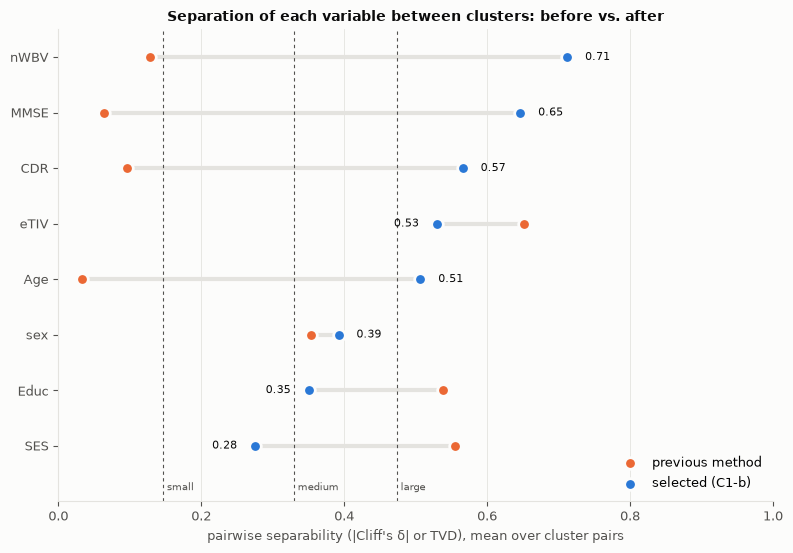

In [3]:
psi = pd.concat([psi_column(df, before, "previous method"), psi_column(df, after, f"selected ({SEL})")], axis=1)
psi.to_csv(OUT / "psi_before_after.csv")
display(format_psi_table(psi))
fig = psi_before_after(psi.iloc[:-1], before=psi.columns[0], after=psi.columns[1])
fig.savefig(OUT / "psi_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Cluster profiles: previous method

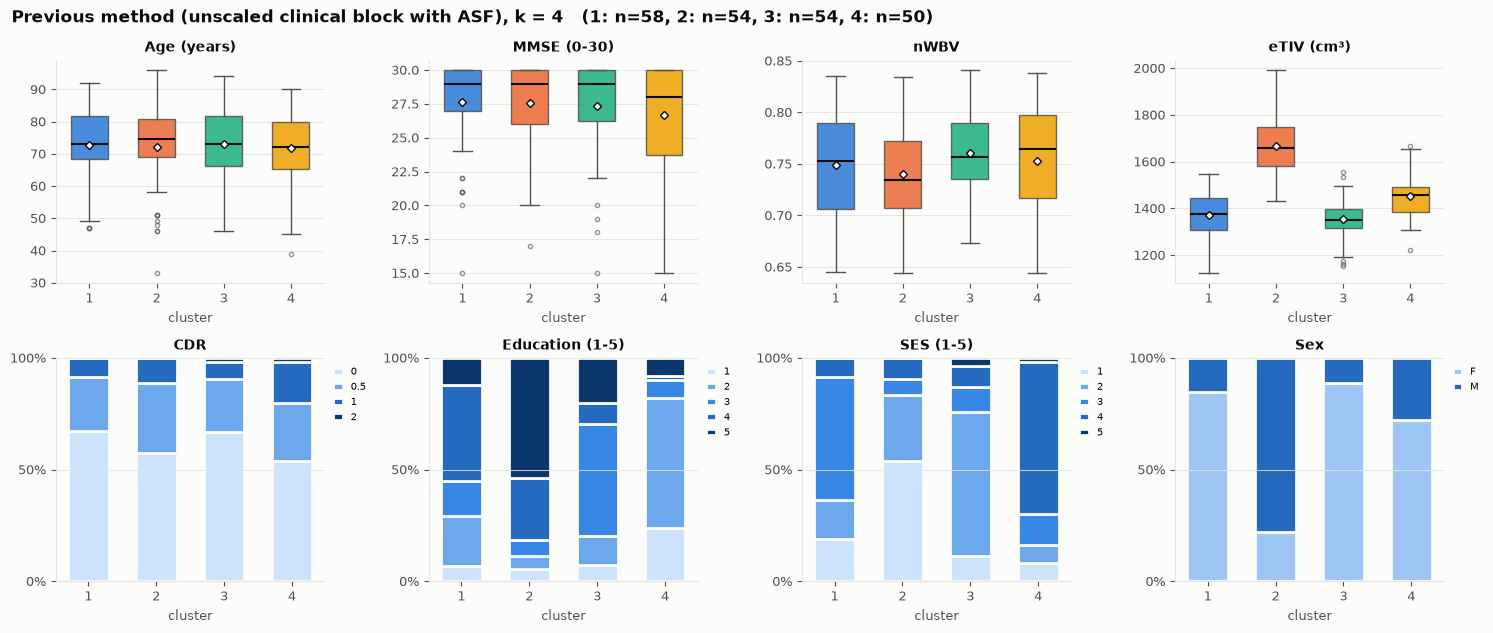

In [4]:
fig = cluster_profile(df, before, "Previous method (unscaled clinical block with ASF), k = 4")
fig.savefig(OUT / "profile_before.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Cluster profiles: selected configuration

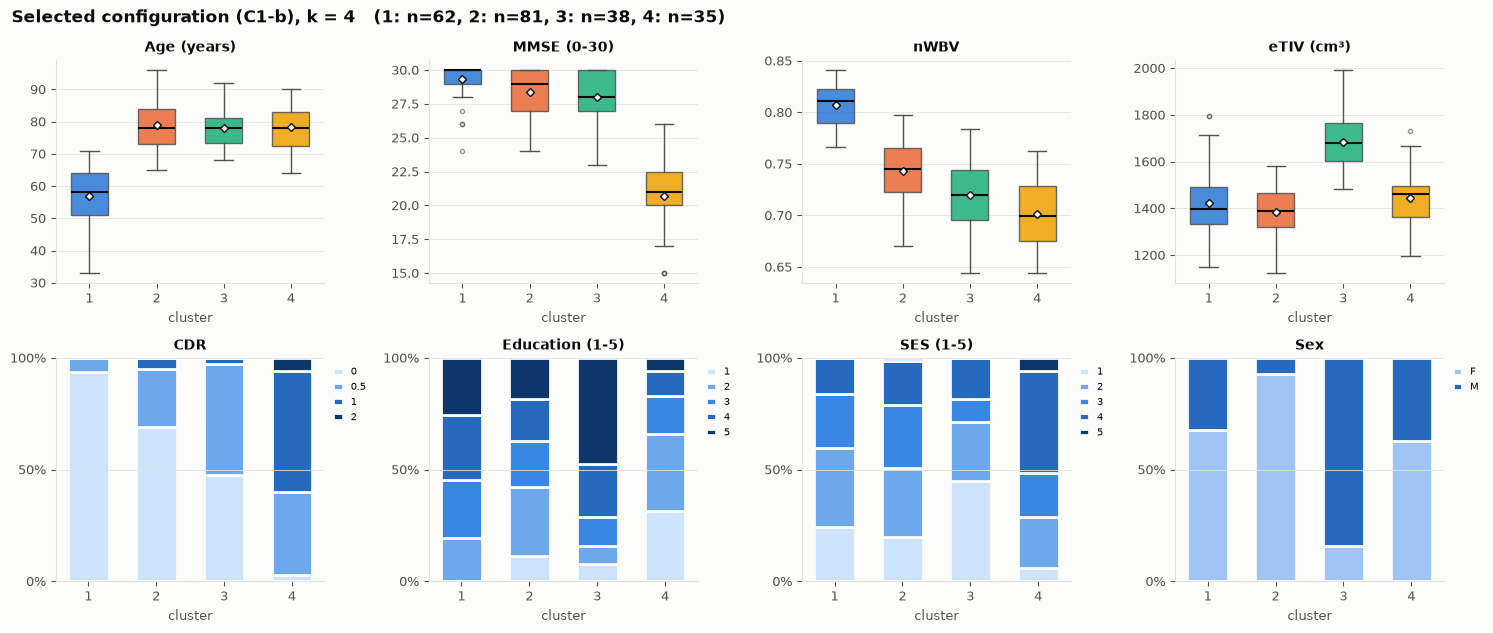

In [5]:
fig = cluster_profile(df, after, f"Selected configuration ({SEL}), k = 4")
fig.savefig(OUT / "profile_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. The clusters as dots

Each dot is a patient. The map is a two-dimensional multidimensional scaling (MDS) of the distance each method
clustered on, so patients that the method considers similar are close together. The axes have no units, and a
2-D map cannot show everything in a high-dimensional distance.

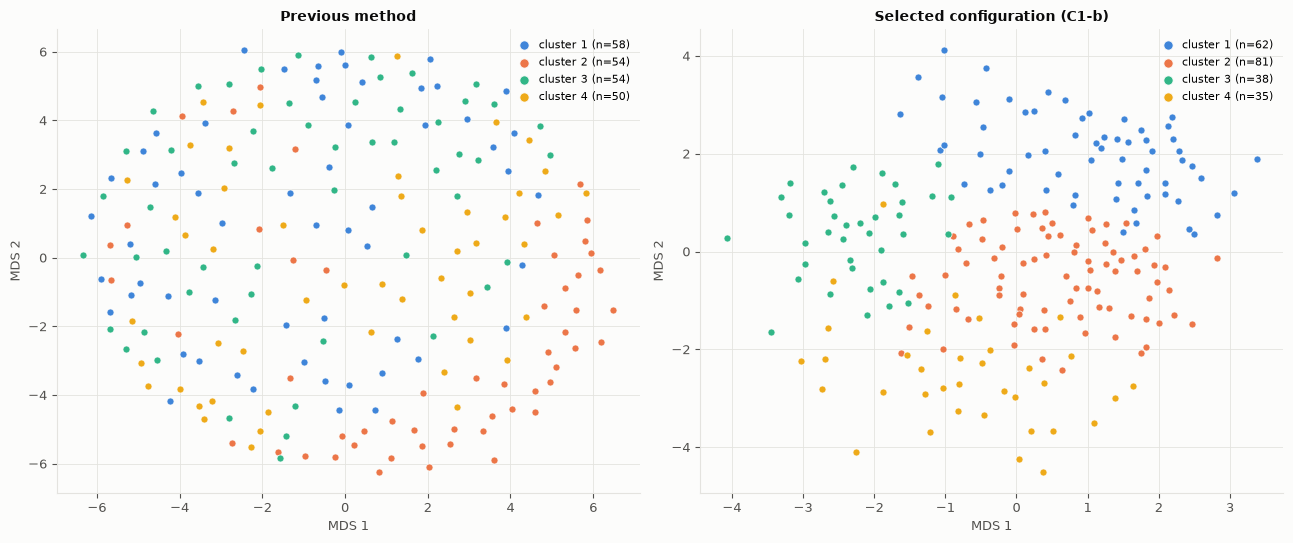

In [6]:
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform

D_after = squareform(pdist(build_kmeans_matrix(df, cfg.CONFIGS[SEL])["X"]))

def mds(D):
    return MDS(n_components=2, metric="precomputed", init="random", n_init=4, random_state=42).fit_transform(D)

xy_before, xy_after = mds(D_old), mds(D_after)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
cluster_scatter(axes[0], xy_before[:, 0], xy_before[:, 1], before, "Previous method", "MDS 1", "MDS 2")
cluster_scatter(axes[1], xy_after[:, 0], xy_after[:, 1], after, f"Selected configuration ({SEL})", "MDS 1", "MDS 2")
fig.tight_layout()
fig.savefig(OUT / "mds_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. What changed

- With the previous method, the clusters differ mainly in head size (eTIV), sex, education and SES, while MMSE, CDR,
  age and brain volume hardly differ between them (PSI 0.03 to 0.13): the unscaled clinical block was in practice an
  eTIV distance.
- With the selected configuration, age, brain volume and cognition separate the clusters clearly (MMSE 0.65,
  CDR 0.57, nWBV 0.71, Age 0.51), and one cluster is a clear cognitively impaired group.
- Sex and head size still separate one cluster (sex 0.39, eTIV 0.53): with sex in the multiclass block, one cluster
  is mostly men with large heads. Education and SES separate the clusters less than before (0.35 and 0.28).